# Módulo 4 · Ejercicio 1 · Opción A
## Telemetría IoT en tiempo real e ingesta en Delta Lake

Pipeline de **Spark Structured Streaming** sobre **Databricks** que lee telemetría
de vehículos (GPS, velocidad y nivel de batería) desde un directorio de ficheros
JSON en almacenamiento cloud, la parsea, limpia las anomalías y la guarda en una
tabla **Delta Lake particionada por ciudad**.

### De dónde salen los datos

La base es el **[Vehicle Energy Dataset](https://github.com/gsoh/VED)** (Universidad
de Michigan, licencia Apache-2.0): 27 coches eléctricos reales medidos por OBD-II a
1 registro por segundo en Ann Arbor, Michigan. De ahí salen las tres señales que
pide el enunciado (posición GPS, `Vehicle Speed[km/h]` y `HV Battery SOC[%]`),
medidas de verdad y no inventadas.

El enunciado pide datos *simulados*, así que la sección 2 monta una flota
multi-ciudad encima de esos datos reales. Cambia dos cosas y solo dos:

1. **La geografía.** VED es de una sola ciudad y particionar por ciudad no tendría
   ninguna gracia. Cada vehículo se asigna a una de 5 ciudades españolas y su
   recorrido se traslada allí, reescalando la longitud por `cos(latitud)` para no
   deformar las distancias.
2. **El tamaño de la flota.** Solo 27 coches miden la batería, que entre 5 ciudades
   salen a 5 por ciudad. Se usa el **viaje** como unidad: cada viaje real pasa a ser
   un coche distinto, lo que da 1.590 vehículos. Vale porque entre viajes el coche
   se recarga, o sea que un viaje ya es independiente del anterior.

La velocidad y la batería no se tocan en ningún momento.

Los viajes reales duran hasta 96 minutos y aquí se reproducen 60 veces más rápido,
así que el más largo ocupa poco más de un minuto. A escala real, un solo evento del
final de un viaje largo empujaría el reloj interno de Spark casi una hora hacia
delante y el resto se descartaría por atrasado.

El generador estropea a propósito una parte de los registros y apunta cuáles en un
manifiesto. Cada registro recibe como mucho un fallo, así que al final se puede
comparar cifra contra cifra lo que se rompió y lo que se detectó.

### El recorrido de los datos

```
generador (hilo)  ──JSON──▶  <raiz>/lake/landing/
                                  │
                        lectura en streaming
                                  ▼
                         BRONCE   datos crudos, anomalías incluidas
                                  │
                      quitar duplicados (watermark)
                                  │
                           aplicar reglas
                            ╱           ╲
                        PLATA          CUARENTENA
                 particionada          las filas que fallaron,
                 por ciudad            con el motivo
                            ╲           ╱
                              consultas
                                  ▼
                        ORO   resumen por ciudad · calidad de datos
```

---
## 0. Requisitos previos

Tres cosas antes de ejecutar.

1. **Cómputo.** Cualquier cluster con Databricks Runtime 13.3 LTS o superior. Delta
   Lake, PySpark, pandas y matplotlib vienen incluidos, así que no hay que instalar
   nada ni crear la `SparkSession`.
2. **Los datos.** Subir `semilla_ved.parquet` (12 MB) a un volumen: *Catalog* → tu
   catálogo → tu esquema → *Create* → *Volume* → `telemetria`, y *Upload to volume*.
   Queda en `/Volumes/<catalogo>/<esquema>/telemetria/semilla_ved.parquet`.
3. **Dónde vive el lake.** La celda siguiente tiene un interruptor, `ALMACEN`:

| Valor | Dónde escribe | Cuándo usarlo |
|---|---|---|
| `"volumes"` | Unity Catalog Volume | Por defecto. Vale en clusters clásicos **y** serverless |
| `"dbfs"` | DBFS (`dbfs:/tmp/...`) | Workspaces antiguos sin Unity Catalog |

Si `ALMACEN = "volumes"`, ajusta `CATALOGO`, `ESQUEMA` y `VOLUMEN` a los tuyos.

---
## 1. Preparación

In [0]:
import json, math, random, threading, time, uuid
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from pyspark.sql import functions as F

# Lo unico que hay que tocar.
ALMACEN = "volumes"          # "volumes" o "dbfs"

CATALOGO = "workspace"       # solo se usan si ALMACEN == "volumes"
ESQUEMA  = "default"
VOLUMEN  = "telemetria"

if ALMACEN == "volumes":
    # En un Volume la ruta local y la de Spark son la misma cadena.
    RAIZ_LOCAL = f"/Volumes/{CATALOGO}/{ESQUEMA}/{VOLUMEN}"
    RAIZ_SPARK = RAIZ_LOCAL
elif ALMACEN == "dbfs":
    # DBFS se ve de dos formas: /dbfs/... desde Python (montaje FUSE) y dbfs:/...
    # desde Spark. Apuntan al mismo sitio pero no se pueden mezclar.
    RAIZ_LOCAL = "/dbfs/tmp/telemetria"
    RAIZ_SPARK = "dbfs:/tmp/telemetria"
else:
    raise ValueError('ALMACEN tiene que ser "volumes" o "dbfs"')

SEMILLA = Path(RAIZ_LOCAL) / "semilla_ved.parquet"
LAGO    = Path(RAIZ_LOCAL) / "lake"

LANDING     = LAGO / "landing"
BRONCE      = LAGO / "bronce"
PLATA       = LAGO / "plata"
CUARENTENA  = LAGO / "cuarentena"
ORO_CIUDAD  = LAGO / "oro_ciudades"
ORO_CALIDAD = LAGO / "oro_calidad"
CHECKPOINT  = LAGO / "checkpoints"
GRAFICA     = LAGO / "rendimiento.png"

def ruta(p):
    """Traduce una ruta local a la que entiende Spark.

    Con Volumes es la identidad. Con DBFS convierte /dbfs/x en dbfs:/x, que es la
    confusion que mas errores da en Databricks: Python lee por el montaje FUSE y
    Spark por el esquema dbfs:, y no son intercambiables.
    """
    return str(p).replace("\\", "/").replace(RAIZ_LOCAL, RAIZ_SPARK, 1)

def lotes_de(tabla):
    """Metricas por micro-lote, leidas del log de transacciones de Delta.

    Cada micro-lote deja una version: el sink de streaming la marca como STREAMING
    UPDATE y las escrituras de foreachBatch como WRITE. La duracion es el hueco
    entre commits consecutivos.
    """
    h = (spark.sql(f"DESCRIBE HISTORY delta.`{ruta(tabla)}`")
              .filter("operation IN ('WRITE', 'STREAMING UPDATE')")
              .orderBy("version").collect())
    lotes = []
    for i, r in enumerate(h):
        filas = int(r["operationMetrics"].get("numOutputRows", 0))
        if filas == 0:          # commits sin filas: no son lotes de trabajo
            continue
        ms = 0 if i == 0 else int(
            (r["timestamp"] - h[i - 1]["timestamp"]).total_seconds() * 1000)
        lotes.append({"lote": r["version"], "filas": filas, "ms": ms})
    return lotes


def resumen(nombre, lotes):
    print(f"{nombre}: {sum(l['filas'] for l in lotes):,} filas en {len(lotes)} lotes")


CIUDADES = {
    "Madrid":    (40.4168, -3.7038),
    "Barcelona": (41.3851,  2.1734),
    "Valencia":  (39.4699, -0.3763),
    "Sevilla":   (37.3891, -5.9845),
    "Bilbao":    (43.2630, -2.9350),
}

print("almacen :", ALMACEN)
print("raiz    :", RAIZ_LOCAL)
print("spark   :", ruta(LAGO))
print("ciudades:", ", ".join(CIUDADES))

almacen : volumes
raiz    : /Volumes/workspace/default/telemetria
spark   : /Volumes/workspace/default/telemetria/lake
ciudades: Madrid, Barcelona, Valencia, Sevilla, Bilbao


In [0]:
if not SEMILLA.exists():
    raise FileNotFoundError(
        f"Falta {SEMILLA}. Subela al volumen o corrige ALMACEN / CATALOGO / ESQUEMA / VOLUMEN.")

LAGO.mkdir(parents=True, exist_ok=True)
print(f"semilla: {SEMILLA.stat().st_size / 1e6:.1f} MB")

semilla: 12.3 MB


### Ajustes de la sesión

Los dos últimos parámetros son específicos de Databricks: el runtime compacta las
escrituras por su cuenta, y eso taparía lo que mide la sección 5.

In [0]:
# Con las 200 por defecto salen cientos de tareas vacias para tan pocos datos.
spark.conf.set("spark.sql.shuffle.partitions", "8")

# El generador escribe en UTC con sufijo Z. Sin fijar la zona, el watermark
# compararia contra el reloj del cluster.
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Databricks compacta al escribir, y eso taparia lo que mide la seccion 5. En
# serverless estan bloqueadas y set() lanza.
for clave in ("spark.databricks.delta.optimizeWrite.enabled",
              "spark.databricks.delta.autoCompact.enabled"):
    try:
        spark.conf.set(clave, "false")
    except Exception:
        pass

print("Spark", spark.version)
print("shuffle.partitions:", spark.conf.get("spark.sql.shuffle.partitions"))

Spark 4.2.0
shuffle.partitions: 8


---
## 2. El generador

Escribe un fichero JSON cada 2 segundos en `landing/`, en un hilo aparte, para que
produzca datos mientras el pipeline los consume.

En la versión local esto era un `generador.py` lanzado con `subprocess`. En un
notebook de Databricks no hay otra terminal donde lanzarlo, así que va embebido y
corre en un `threading.Thread`.

### Anomalías inyectadas

| Etiqueta | Qué se rompe | Fracción |
|---|---|---|
| `VELOCIDAD_ABSURDA` | velocidad de 300 a 900 km/h | 2,0 % |
| `COORDENADA_IMPOSIBLE` | latitud 999 | 1,5 % |
| `BATERIA_FUERA_DE_RANGO` | batería a −5 o a 150 | 1,5 % |
| `CAMPO_VACIO` | se borra vehículo, ciudad o fecha | 1,5 % |
| `FUERA_DE_CIUDAD` | coordenada válida pero de otra ciudad | 1,0 % |
| `CIUDAD_DESCONOCIDA` | Lisboa, Oporto o Toulouse | 1,0 % |
| `DUPLICADO` | el mismo evento repetido | 1,5 % |
| `EVENTO_TARDIO` | llega con 15–40 minutos de retraso | 1,5 % |

Como mucho un fallo por registro, para que la comprobación 7.4 pueda comparar cifra
contra cifra sin descontar solapamientos.

In [0]:
# Los datos originales se grabaron aqui.
ANN_ARBOR = (42.2808, -83.7430)

# A escala 1:1 un solo evento del final de un viaje de 96 minutos empujaria el
# watermark casi una hora y el resto se tiraria por atrasado.
ACELERACION = 60

ANOMALIAS = {
    "VELOCIDAD_ABSURDA":      0.020,
    "COORDENADA_IMPOSIBLE":   0.015,
    "BATERIA_FUERA_DE_RANGO": 0.015,
    "CAMPO_VACIO":            0.015,
    "FUERA_DE_CIUDAD":        0.010,
    "CIUDAD_DESCONOCIDA":     0.010,
    "DUPLICADO":              0.015,
    "EVENTO_TARDIO":          0.015,
}


def preparar(inicio):
    """Carga la semilla y la convierte en telemetria de una flota multi-ciudad."""
    df = pd.read_parquet(SEMILLA)

    # Solo 27 coches de VED miden la bateria, asi que saldrian 5 por ciudad. Se usa
    # el viaje como unidad de flota: entre viajes el coche se recarga, o sea que un
    # viaje ya es independiente del anterior.
    df["flota_id"] = df.groupby(["veh_id", "trip"]).ngroup()
    df["city"] = [list(CIUDADES)[i % len(CIUDADES)] for i in df["flota_id"]]

    # Las marcas de tiempo son de 2017. Se recolocan en el presente (y aceleradas)
    # para que Spark las trate como eventos que acaban de ocurrir.
    t0 = df.groupby("flota_id")["ts_ms"].transform("min")
    df["event_ts"] = inicio + pd.to_timedelta((df["ts_ms"] - t0) / ACELERACION, unit="ms")

    # Traslacion de Ann Arbor a cada ciudad. Un grado de longitud mide distinto
    # segun la latitud (82 km en Ann Arbor, 88 en Sevilla), asi que la diferencia
    # en longitud se reescala; si no, las distancias saldrian mal.
    lat0, lon0 = ANN_ARBOR
    lat_ciudad = np.array([CIUDADES[c][0] for c in df["city"]])
    lon_ciudad = np.array([CIUDADES[c][1] for c in df["city"]])
    escala = math.cos(math.radians(lat0)) / np.cos(np.radians(lat_ciudad))
    df["lat"] = df["lat"] - lat0 + lat_ciudad
    df["lon"] = (df["lon"] - lon0) * escala + lon_ciudad

    # Barajadas para que cada fichero toque varias ciudades y las particiones se
    # llenen en paralelo. Cada registro lleva su propia marca de tiempo.
    return df.sample(frac=1, random_state=0).reset_index(drop=True)


def registro(fila):
    return {
        "event_id":    str(uuid.uuid4()),
        "vehicle_id":  f"VEH-{fila.flota_id:05d}",
        "city":        fila.city,
        "event_ts":    fila.event_ts,
        "lat":         round(float(fila.lat), 6),
        "lon":         round(float(fila.lon), 6),
        "speed_kmh":   float(fila.speed_kmh),
        "battery_pct": float(fila.battery_pct),
        "trip_id":     f"{fila.veh_id}-{fila.trip}",
    }


def romper(reg, rnd):
    """Estropea el registro, o no. Devuelve el nombre del fallo aplicado o None."""
    tirada, acumulado = rnd.random(), 0.0
    for fallo, probabilidad in ANOMALIAS.items():
        acumulado += probabilidad
        if tirada >= acumulado:
            continue

        if fallo == "VELOCIDAD_ABSURDA":
            reg["speed_kmh"] = round(rnd.uniform(300, 900), 1)
        elif fallo == "COORDENADA_IMPOSIBLE":
            reg["lat"] = 999.0
        elif fallo == "BATERIA_FUERA_DE_RANGO":
            reg["battery_pct"] = rnd.choice([-5.0, 150.0])
        elif fallo == "CAMPO_VACIO":
            reg[rnd.choice(["vehicle_id", "city", "event_ts"])] = None
        elif fallo == "FUERA_DE_CIUDAD":
            # Coordenada perfectamente valida, pero de otra ciudad: el coche dice
            # estar en Madrid y aparece en Bilbao.
            otra = rnd.choice([c for c in CIUDADES if c != reg["city"]])
            reg["lat"], reg["lon"] = CIUDADES[otra]
        elif fallo == "CIUDAD_DESCONOCIDA":
            reg["city"] = rnd.choice(["Lisboa", "Oporto", "Toulouse"])
        elif fallo == "EVENTO_TARDIO":
            reg["event_ts"] = reg["event_ts"] - timedelta(minutes=rnd.randint(15, 40))
        # DUPLICADO no toca el registro: lo repite quien llama.
        return fallo
    return None


def escribir(registros, n):
    """Guarda un lote como JSON, una linea por evento."""
    lineas = []
    for reg in registros:
        reg = dict(reg)
        if reg["event_ts"] is not None:
            reg["event_ts"] = reg["event_ts"].isoformat().replace("+00:00", "Z")
        lineas.append(json.dumps(reg))

    # Se renombra al final, y ademas el readStream filtra por *.json (seccion 3),
    # asi que un fichero a medio escribir nunca entra.
    tmp = LANDING / f"lote-{n:04d}.escribiendo"
    tmp.write_text("\n".join(lineas), encoding="utf-8")
    tmp.rename(LANDING / f"lote-{n:04d}.json")


# Un hilo no puede propagar excepciones al notebook, asi que las deja aqui.
estado_generador = {"error": None, "ficheros": 0, "eventos": 0}


def generar(duracion=60, intervalo=2, tamano=500, semilla_azar=42):
    """Bucle del generador. Pensado para correr en un hilo aparte."""
    try:
        rnd = random.Random(semilla_azar)
        inicio = pd.Timestamp(datetime.now(timezone.utc)).floor("s")
        df = preparar(inicio)

        manifiesto = (LANDING / "_manifiesto.jsonl").open("w", encoding="utf-8")
        fin = time.time() + duracion
        n, pos = 0, 0

        while time.time() < fin and pos < len(df):
            lote, cuenta = [], {}
            for fila in df.iloc[pos:pos + tamano].itertuples():
                reg = registro(fila)
                fallo = romper(reg, rnd)
                if fallo:
                    cuenta[fallo] = cuenta.get(fallo, 0) + 1
                lote.append(reg)
                if fallo == "DUPLICADO":
                    lote.append(dict(reg))
            pos += tamano

            escribir(lote, n)
            # Contra esto comprueba despues la seccion 7 que la limpieza hizo su trabajo.
            manifiesto.write(json.dumps({"fichero": f"lote-{n:04d}.json",
                                         "filas": len(lote), "anomalias": cuenta}) + "\n")
            manifiesto.flush()

            n += 1
            estado_generador["ficheros"] = n
            estado_generador["eventos"] += len(lote)
            time.sleep(intervalo)

        manifiesto.close()
    except Exception as e:
        estado_generador["error"] = e

print("generador definido")

generador definido


### El trigger, y por qué cambia el orden

El cómputo serverless no admite streaming continuo:

```
[INFINITE_STREAMING_TRIGGER_NOT_SUPPORTED] Trigger type ProcessingTime is not
supported for this cluster type. Use a different trigger type e.g. AvailableNow, Once.
```

Así que las dos consultas usan `Trigger.AvailableNow`: procesan todo lo que hay
pendiente, en micro-lotes, y terminan solas. Eso obliga a generar los datos antes de
arrancar el flujo, en vez de a la vez.

Sigue siendo Structured Streaming y sigue ejerciendo lo mismo: checkpoints, offsets,
watermark, estado de `dropDuplicates` y `foreachBatch`. `maxFilesPerTrigger` se
respeta igual, así que el trabajo se sigue partiendo en varios micro-lotes y las
métricas por lote de la sección 9 siguen saliendo.

Lo que se pierde es la concurrencia entre productor y consumidor. En un cluster
clásico basta con cambiar `.trigger(availableNow=True)` por
`.trigger(processingTime="5 seconds")` en las dos consultas y lanzar el generador en
paralelo, que es lo que hace la versión local.

### Arrancarlo

In [0]:
for d in (LANDING, BRONCE, PLATA, CUARENTENA, ORO_CIUDAD, ORO_CALIDAD, CHECKPOINT):
    dbutils.fs.rm(ruta(d), True)
LANDING.mkdir(parents=True, exist_ok=True)

hilo = threading.Thread(target=generar,
                        kwargs=dict(duracion=60, intervalo=2, tamano=500),
                        daemon=True, name="generador")
hilo.start()
print("generador arrancado (60 segundos)")

# Con AvailableNow el flujo consume lo que ya existe, asi que hay que generarlo todo
# antes de arrancarlo.
hilo.join()
if estado_generador["error"]:
    raise estado_generador["error"]
print(f"{estado_generador['ficheros']} ficheros, {estado_generador['eventos']:,} eventos")

generador arrancado (60 segundos)
26 ficheros, 13,204 eventos


---
## 3. Capa Bronce: los datos tal y como llegan

Bronce guarda **exactamente lo que llegó**, anomalías incluidas. Así se puede
reprocesar más adelante con otras reglas de limpieza sin volver a pedir nada al
origen.

Tres decisiones:

- **El esquema se escribe a mano.** En streaming nunca se deja que Spark lo deduzca:
  tendría que leer los datos en cada vuelta para averiguarlo, y el esquema podría
  cambiar de un fichero a otro sin que nadie se entere.
- **`event_ts` se declara como texto**, no como fecha. Si fuese fecha, Spark
  convertiría en `null` cualquier valor mal formado y ya no se podría distinguir
  "no llegó la fecha" de "llegó una fecha inválida". La conversión se hace luego.
- **`pathGlobFilter` limita la lectura a `*.json`.** El generador escribe primero un
  `.escribiendo` y lo renombra al terminar. Sobre almacenamiento cloud ese renombrado
  no es instantáneo, así que sin el filtro Spark podría leer un fichero a medias.

In [0]:
from pyspark.sql.types import DoubleType, StringType, StructField, StructType

ESQUEMA_JSON = StructType([
    StructField("event_id",    StringType()),
    StructField("vehicle_id",  StringType()),
    StructField("city",        StringType()),
    StructField("event_ts",    StringType()),
    StructField("lat",         DoubleType()),
    StructField("lon",         DoubleType()),
    StructField("speed_kmh",   DoubleType()),
    StructField("battery_pct", DoubleType()),
    StructField("trip_id",     StringType()),
])

bronce = (
    spark.readStream.format("json")
        .schema(ESQUEMA_JSON)
        # Sin esto la primera vuelta se traga de golpe todo lo que haya. En produccion
        # es ademas el freno que evita un OOM al reanudar tras una caida.
        .option("maxFilesPerTrigger", 3)
        .option("pathGlobFilter", "*.json")
        .load(ruta(LANDING))
        .withColumn("_recibido", F.current_timestamp())
        # input_file_name() esta prohibido en Unity Catalog; _metadata es el
        # equivalente que si admite.
        .withColumn("_fichero", F.col("_metadata.file_path"))
)

consulta_bronce = (
    bronce.writeStream.format("delta").outputMode("append")
        .queryName("landing_a_bronce")
        .option("checkpointLocation", ruta(CHECKPOINT / "bronce"))
        .trigger(availableNow=True)
        .start(ruta(BRONCE))
)

consulta_bronce.awaitTermination()
progreso_bronce = lotes_de(BRONCE)
resumen("bronce", progreso_bronce)

bronce: 13,204 filas en 9 lotes


---
## 4. Capa Plata: limpieza y partición por ciudad

### Las reglas

Cada fila se comprueba contra seis reglas. Las que fallan alguna van a
**cuarentena** con la lista de motivos; las que pasan todas van a **plata**.

| Regla | Se rechaza cuando | Etiqueta |
|---|---|---|
| Velocidad | vacía, negativa o mayor de 200 km/h | `VELOCIDAD_ABSURDA` |
| Coordenadas | vacías o fuera del rango de la Tierra | `COORDENADA_IMPOSIBLE` |
| Coherencia | el punto está a más de 0,5° del centro de su ciudad | `FUERA_DE_CIUDAD` |
| Batería | vacía, negativa o mayor de 100 | `BATERIA_FUERA_DE_RANGO` |
| Claves | falta el vehículo, la ciudad o la fecha | `CAMPO_VACIO` |
| Ciudad | la ciudad no es ninguna de las cinco | `CIUDAD_DESCONOCIDA` |

Las etiquetas son **las mismas** que usa el generador al estropear los datos. Eso
permite comparar al final, uno a uno, lo que se rompió contra lo que se detectó.

Una fila puede incumplir varias reglas a la vez y se apuntan todas, no solo la
primera.

`FUERA_DE_CIUDAD` solo se comprueba si las coordenadas son válidas: no tiene
sentido medir a qué distancia de Madrid está un punto con latitud 999.

In [0]:
MAX_VELOCIDAD = 200.0
RADIO_CIUDAD  = 0.5     # grados alrededor del centro de la ciudad

def marcar_problemas(df):
    """Anade la columna `problemas` con las reglas que incumple cada fila."""
    lat_centro = F.create_map(*[x for ciudad, (la, lo) in CIUDADES.items()
                                for x in (F.lit(ciudad), F.lit(la))])[F.col("city")]
    lon_centro = F.create_map(*[x for ciudad, (la, lo) in CIUDADES.items()
                                for x in (F.lit(ciudad), F.lit(lo))])[F.col("city")]

    coords_rotas = (F.col("lat").isNull() | F.col("lon").isNull()
                    | ~F.col("lat").between(-90, 90)
                    | ~F.col("lon").between(-180, 180))

    lejos = (~coords_rotas
             & ((F.abs(F.col("lat") - lat_centro) > RADIO_CIUDAD)
                | (F.abs(F.col("lon") - lon_centro) > RADIO_CIUDAD)))

    reglas = [
        (F.col("speed_kmh").isNull() | ~F.col("speed_kmh").between(0, MAX_VELOCIDAD),
         "VELOCIDAD_ABSURDA"),
        (coords_rotas, "COORDENADA_IMPOSIBLE"),
        (lejos, "FUERA_DE_CIUDAD"),
        (F.col("battery_pct").isNull() | ~F.col("battery_pct").between(0, 100),
         "BATERIA_FUERA_DE_RANGO"),
        (F.col("vehicle_id").isNull() | F.col("city").isNull() | F.col("event_ts").isNull(),
         "CAMPO_VACIO"),
        (F.col("city").isNotNull() & ~F.col("city").isin(list(CIUDADES)),
         "CIUDAD_DESCONOCIDA"),
    ]
    # Vacia y no null: size(null) devuelve -1 y romperia el filtro de despues.
    return df.withColumn("problemas", F.array_compact(
        F.array(*[F.when(cond, F.lit(etiqueta)) for cond, etiqueta in reglas])))


def anadir_columnas(df):
    """Columnas calculadas que solo tienen sentido sobre datos ya limpios."""
    return (df
        .withColumn("en_movimiento", F.col("speed_kmh") > 1.0)
        .withColumn("nivel_bateria",
                    F.when(F.col("battery_pct") < 10, "CRITICO")
                     .when(F.col("battery_pct") < 25, "BAJO")
                     .when(F.col("battery_pct") < 60, "MEDIO")
                     .otherwise("ALTO")))

print("reglas definidas")

reglas definidas


### Duplicados y eventos que llegan tarde

```python
.withWatermark("event_ts", "10 minutes").dropDuplicates(["event_id"])
```

El watermark es lo que permite a Spark olvidar los eventos viejos que guarda para
detectar duplicados. Sin él esa memoria crece sin parar.

El precio es que los eventos que llegan con más de 10 minutos de retraso se
descartan sin avisar. Por eso al final **bronce no es exactamente plata más
cuarentena**, y esa diferencia hay que medirla en vez de darla por buena.

### Dos tablas desde un solo flujo

`writeStream` solo admite un destino, pero necesitamos escribir plata **y**
cuarentena. `foreachBatch` da acceso a cada lote ya calculado y dentro se puede
escribir tantas veces como haga falta.

In [0]:
def guardar(lote, lote_id):
    """Parte cada lote en dos y escribe las dos tablas Delta.

    El lote se recorre dos veces, una por tabla. En un cluster clasico se cachearia
    con persist(), pero serverless lo rechaza con NOT_SUPPORTED_WITH_SERVERLESS y
    con lotes de unos miles de filas el recalculo no se nota.
    """
    limpias = anadir_columnas(lote.filter(F.size("problemas") == 0)).drop("problemas")
    sucias  = lote.filter(F.size("problemas") > 0)

    limpias.write.format("delta").mode("append").partitionBy("city").save(ruta(PLATA))
    sucias.write.format("delta").mode("append").save(ruta(CUARENTENA))


entrada_plata = marcar_problemas(
    spark.readStream.format("delta")
        # Sin esto Delta se traeria las 1.000 versiones por defecto en un solo lote y
        # foreachBatch se ejecutaria una unica vez.
        .option("maxFilesPerTrigger", 3)
        .load(ruta(BRONCE))
        .withColumn("event_ts", F.to_timestamp("event_ts"))
        .withWatermark("event_ts", "10 minutes")
        .dropDuplicates(["event_id"])
)

consulta_plata = (
    entrada_plata.writeStream
        .foreachBatch(guardar)
        .queryName("bronce_a_plata")
        # Un checkpoint por consulta: compartirlo corrompe el avance de las dos.
        .option("checkpointLocation", ruta(CHECKPOINT / "plata"))
        .trigger(availableNow=True)
        .start()
)

consulta_plata.awaitTermination()
progreso_plata = lotes_de(PLATA)
resumen("plata", progreso_plata)

plata: 11,931 filas en 3 lotes


### Métricas por lote

Con `AvailableNow` no hay panel en vivo que mirar: las consultas ya terminaron.

El cómputo serverless devuelve `recentProgress` con `numInputRows` a `None`, así que
las métricas se leen del **log de transacciones de Delta**: cada micro-lote deja una
versión con las filas que escribió y su marca de tiempo, y el hueco entre commits
consecutivos es lo que tardó. Es la misma información y no depende de qué exponga el
runtime.

Para las capturas del informe:

- Debajo de las dos celdas anteriores hay un panel con las gráficas de *input rate*,
  *processing rate* y *batch duration*. Se queda incrustado al exportar el notebook.
- *Compute* → tu cluster → *Spark UI* → *Structured Streaming*, para el detalle por
  consulta.
- El DAG está en *Spark UI* → *Jobs* → cualquier job → *DAG Visualization*.

In [0]:
progreso = {"landing_a_bronce": progreso_bronce, "bronce_a_plata": progreso_plata}

for nombre, lotes in progreso.items():
    print(f"{nombre}")
    print(f"  {'lote':>5}{'filas':>10}{'ms':>10}")
    for l in lotes:
        print(f"  {l['lote']:>5}{l['filas']:>10,}{l['ms']:>10,}")
    print()

landing_a_bronce
   lote     filas        ms
      1     1,522     1,000
      2     1,523     1,000
      3     1,516     1,000
      4     1,531     1,000
      5     1,522     2,000
      6     1,527     1,000
      7     1,523     1,000
      8     1,527     1,000
      9     1,013     2,000

bronce_a_plata
   lote     filas        ms
      0     4,132         0
      1     4,118     3,000
      2     3,681     3,000



---
## 5. Compactar las tablas

El streaming escribe al menos un fichero por lote y por partición, así que salen
decenas de ficheros de pocos KB y leerlos cuesta más en abrirlos que en leer los
datos. `OPTIMIZE` los junta y `ZORDER` coloca juntas las filas del
mismo vehículo para que las consultas puedan saltarse ficheros enteros.

En la celda de configuración se apagaron `optimizeWrite` y `autoCompact`. Con ellos
activos, Databricks ya habría compactado y este `OPTIMIZE` no tendría nada que hacer.

In [0]:
def ficheros_activos(tabla):
    # Los que usa ahora. Los .parquet viejos siguen guardados hasta el VACUUM.
    return spark.sql(f"DESCRIBE DETAIL delta.`{ruta(tabla)}`").collect()[0]["numFiles"]

antes = ficheros_activos(PLATA)
spark.sql(f"OPTIMIZE delta.`{ruta(PLATA)}` ZORDER BY (vehicle_id, event_ts)")
spark.sql(f"OPTIMIZE delta.`{ruta(CUARENTENA)}`")
despues = ficheros_activos(PLATA)

en_disco = len(list(PLATA.rglob("*.parquet")))
print(f"ficheros que usa plata: {antes} antes -> {despues} despues del OPTIMIZE")
print(f"ficheros que hay en disco: {en_disco} (los viejos esperan a un VACUUM)")

ficheros que usa plata: 15 antes -> 5 despues del OPTIMIZE
ficheros que hay en disco: 20 (los viejos esperan a un VACUUM)


---
## 6. Capa Oro: las consultas

Se calcula en lote y no en streaming: los kilómetros recorridos necesitan comparar
cada punto con el anterior del mismo vehículo (`lag`), y esa función no está
permitida dentro de una agregación en streaming.

La distancia se calcula con la **fórmula de haversine** y no restando grados: un
grado de longitud mide unos 81 km en Bilbao y unos 88 en Sevilla, así que restar
grados metería un error distinto en cada ciudad, justo en la dimensión por la que
estamos agrupando.

In [0]:
from pyspark.sql import Window

plata = spark.read.format("delta").load(ruta(PLATA))

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos de la Tierra."""
    a = (F.sin(F.radians(lat2 - lat1) / 2) ** 2
         + F.cos(F.radians(lat1)) * F.cos(F.radians(lat2))
         * F.sin(F.radians(lon2 - lon1) / 2) ** 2)
    return F.lit(2 * 6371.0088) * F.asin(F.sqrt(a))

orden = Window.partitionBy("vehicle_id", "trip_id").orderBy("event_ts")

con_distancia = (
    plata
    .withColumn("lat_ant", F.lag("lat").over(orden))
    .withColumn("lon_ant", F.lag("lon").over(orden))
    .withColumn("tramo_km", F.when(F.col("lat_ant").isNull(), F.lit(0.0))
                             .otherwise(haversine(F.col("lat_ant"), F.col("lon_ant"),
                                                  F.col("lat"), F.col("lon"))))
    # Mas de 1 km entre dos medidas de 1 Hz son 3.600 km/h: es un hueco en la
    # grabacion, no un desplazamiento.
    .withColumn("tramo_km", F.when(F.col("tramo_km") > 1.0, F.lit(0.0))
                             .otherwise(F.col("tramo_km")))
)

oro_ciudades = (
    con_distancia.groupBy("city").agg(
        F.count("*").alias("eventos"),
        F.countDistinct("vehicle_id").alias("vehiculos"),
        F.round(F.sum("tramo_km"), 1).alias("km_recorridos"),
        F.round(F.avg("speed_kmh"), 1).alias("velocidad_media"),
        F.round(F.avg(F.when(F.col("en_movimiento"), F.col("speed_kmh"))), 1)
         .alias("velocidad_en_marcha"),
        F.round(F.max("speed_kmh"), 1).alias("velocidad_maxima"),
        F.round(F.avg("battery_pct"), 1).alias("bateria_media"),
        F.round(100.0 * F.avg(F.when(F.col("nivel_bateria") == "CRITICO", 1.0)
                               .otherwise(0.0)), 1).alias("pct_bateria_critica"),
    ).orderBy("city")
)

oro_ciudades.write.format("delta").mode("overwrite").save(ruta(ORO_CIUDAD))
display(oro_ciudades)

city,eventos,vehiculos,km_recorridos,velocidad_media,velocidad_en_marcha,velocidad_maxima,bateria_media,pct_bateria_critica
Barcelona,2520,304,584.6,40.9,45.2,124.6,31.3,48.6
Bilbao,2319,296,503.9,38.6,43.5,132.8,30.7,52.2
Madrid,2411,292,544.7,38.9,43.2,131.9,32.5,47.1
Sevilla,2347,303,534.8,39.0,43.7,128.1,37.0,43.3
Valencia,2334,296,536.5,39.2,44.0,120.5,33.5,46.9


In [0]:
cuarentena = spark.read.format("delta").load(ruta(CUARENTENA))

oro_calidad = (
    cuarentena
    .withColumn("motivo", F.explode("problemas"))
    .withColumn("city", F.coalesce("city", F.lit("(sin ciudad)")))
    .groupBy("motivo", "city").agg(F.count("*").alias("filas"))
    .orderBy(F.desc("filas"))
)

oro_calidad.write.format("delta").mode("overwrite").save(ruta(ORO_CALIDAD))
display(oro_calidad)

motivo,city,filas
CAMPO_VACIO,(sin ciudad),65
VELOCIDAD_ABSURDA,Sevilla,61
CIUDAD_DESCONOCIDA,Lisboa,52
BATERIA_FUERA_DE_RANGO,Barcelona,51
VELOCIDAD_ABSURDA,Barcelona,49
VELOCIDAD_ABSURDA,Bilbao,49
VELOCIDAD_ABSURDA,Valencia,48
BATERIA_FUERA_DE_RANGO,Valencia,45
COORDENADA_IMPOSIBLE,Madrid,40
COORDENADA_IMPOSIBLE,Bilbao,40


---
## 7. Comprobaciones

### 7.1 ¿Cuadran las filas?

La cuenta que tiene que salir:

```
bronce = plata + cuarentena + duplicados quitados + descartados por llegar tarde
```

La última parte no se puede medir directamente, porque Spark descarta los eventos
atrasados sin decir nada, así que se obtiene por diferencia y se compara con los
`EVENTO_TARDIO` que el generador inyectó. Si se parecen, cuadra.

In [0]:
manifiesto = [json.loads(l) for l in
              (LANDING / "_manifiesto.jsonl").read_text(encoding="utf-8").splitlines()]
roto = {}
for entrada in manifiesto:
    for motivo, n in entrada["anomalias"].items():
        roto[motivo] = roto.get(motivo, 0) + n
n_generadas = sum(e["filas"] for e in manifiesto)

bronce_tabla = spark.read.format("delta").load(ruta(BRONCE))
n_bronce = bronce_tabla.count()
n_plata  = plata.count()
n_cuar   = cuarentena.count()
n_dup    = n_bronce - bronce_tabla.select("event_id").distinct().count()
resto    = n_bronce - n_plata - n_cuar - n_dup

print(f"  generadas por el generador  {n_generadas:>8,}")
print(f"  leidas en bronce            {n_bronce:>8,}"
      f"   {'(todas)' if n_bronce == n_generadas else '(quedaron ficheros sin leer)'}")
print()
print(f"  plata                       {n_plata:>8,}")
print(f"  cuarentena                  {n_cuar:>8,}")
print(f"  duplicados quitados         {n_dup:>8,}")
print(f"  {'-'*38}")
print(f"  diferencia                  {resto:>8,}   <- descartados por el watermark")
print(f"  eventos tardios inyectados  {roto.get('EVENTO_TARDIO', 0):>8,}   <- deberia parecerse")

  generadas por el generador    13,204
  leidas en bronce              13,204   (todas)

  plata                         11,931
  cuarentena                     1,069
  duplicados quitados              204
  --------------------------------------
  diferencia                         0   <- descartados por el watermark
  eventos tardios inyectados       192   <- deberia parecerse


### 7.2 ¿Está particionado por ciudad?

Es el requisito literal del enunciado: tiene que haber una carpeta por ciudad.

In [0]:
carpetas = sorted(f.name.rstrip("/") for f in dbutils.fs.ls(ruta(PLATA))
                  if f.name.startswith("city="))
print("carpetas en el almacenamiento:", carpetas)
plata.groupBy("city").count().orderBy("city").show()

carpetas en el almacenamiento: ['city=Barcelona', 'city=Bilbao', 'city=Madrid', 'city=Sevilla', 'city=Valencia']
+---------+-----+
|     city|count|
+---------+-----+
|Barcelona| 2520|
|   Bilbao| 2319|
|   Madrid| 2411|
|  Sevilla| 2347|
| Valencia| 2334|
+---------+-----+



### 7.3 ¿Está plata realmente limpia?

Se vuelven a aplicar las reglas sobre la tabla ya escrita. Si la limpieza es
correcta, **ninguna fila** debe incumplir nada.

In [0]:
malas = marcar_problemas(plata).filter(F.size("problemas") > 0).count()
print(f"filas de plata que incumplen alguna regla: {malas}")
print("CORRECTO" if malas == 0 else "MAL: alguna regla no funciona")

filas de plata que incumplen alguna regla: 0
CORRECTO


### 7.4 ¿Se detectó lo que se rompió?

La comprobación central. El generador apuntó en `_manifiesto.jsonl` cada registro
que estropeó; aquí se compara contra lo que el pipeline apartó.

Como cada registro se estropea con un solo fallo, las cifras deben **coincidir
exactamente** en las seis reglas.

Las otras dos etiquetas no aparecen en cuarentena, y es lo esperado:

- **`DUPLICADO`** lo quita `dropDuplicates`, no las reglas. Sale en la fila de
  duplicados de la comprobación 7.1.
- **`EVENTO_TARDIO`** genera filas **válidas**: lo que pone a prueba es el
  watermark, no la limpieza. Sale en la diferencia de la comprobación 7.1.

In [0]:
detectado = {r["motivo"]: r["filas"] for r in
             oro_calidad.groupBy("motivo").agg(F.sum("filas").alias("filas")).collect()}

print(f"{'motivo':<24}{'roto':>8}{'detectado':>12}")
print("-" * 44)
for motivo in sorted(set(roto) | set(detectado)):
    esperado, real = roto.get(motivo, 0), detectado.get(motivo, 0)
    if motivo == "DUPLICADO":
        nota = "  lo quita dropDuplicates"
    elif motivo == "EVENTO_TARDIO":
        nota = "  lo descarta el watermark"
    else:
        nota = "  OK" if esperado == real else f"  ojo: faltan {esperado - real}"
    print(f"{motivo:<24}{esperado:>8}{real:>12}{nota}")

motivo                      roto   detectado
--------------------------------------------
BATERIA_FUERA_DE_RANGO       191         191  OK
CAMPO_VACIO                  196         196  OK
CIUDAD_DESCONOCIDA           126         126  OK
COORDENADA_IMPOSIBLE         182         182  OK
DUPLICADO                    204           0  lo quita dropDuplicates
EVENTO_TARDIO                192           0  lo descarta el watermark
FUERA_DE_CIUDAD              131         131  OK
VELOCIDAD_ABSURDA            243         243  OK


---
## 8. Lo que aporta Delta Lake

Cada escritura es una transacción numerada. Eso permite ver qué pasó y volver a
cualquier estado anterior, cosa que con ficheros Parquet sueltos no se puede.

In [0]:
historial = spark.sql(f"DESCRIBE HISTORY delta.`{ruta(PLATA)}`")
display(historial.select("version", "timestamp", "operation", "operationMetrics"))

ultima = historial.agg(F.max("version")).collect()[0][0]
print("la misma tabla en distintos momentos:")
for v in (0, ultima // 2, ultima):
    n = spark.read.format("delta").option("versionAsOf", v).load(ruta(PLATA)).count()
    print(f"  version {v:>2} -> {n:>8,} filas")

version,timestamp,operation,operationMetrics
3,2026-08-29T12:28:38.000Z,OPTIMIZE,"Map(numRemovedFiles -> 15, numRemovedBytes -> 949398, p25FileSize -> 169271, numDeletionVectorsRemoved -> 0, minFileSize -> 167120, numAddedFiles -> 5, maxFileSize -> 180692, p75FileSize -> 174230, p50FileSize -> 170264, numAddedBytes -> 861577)"
2,2026-08-29T12:28:31.000Z,WRITE,"Map(numFiles -> 5, numOutputRows -> 3681, numOutputBytes -> 295895)"
1,2026-08-29T12:28:28.000Z,WRITE,"Map(numFiles -> 5, numOutputRows -> 4118, numOutputBytes -> 326142)"
0,2026-08-29T12:28:25.000Z,WRITE,"Map(numFiles -> 5, numOutputRows -> 4132, numOutputBytes -> 327361)"


la misma tabla en distintos momentos:
  version  0 ->    4,132 filas
  version  1 ->    8,250 filas
  version  3 ->   11,931 filas


---
## 9. Rendimiento del flujo

lotes procesados   3
filas en total     11,931
filas por lote     3977 de media, 4132 maximo
tiempo por lote    3000 ms de media


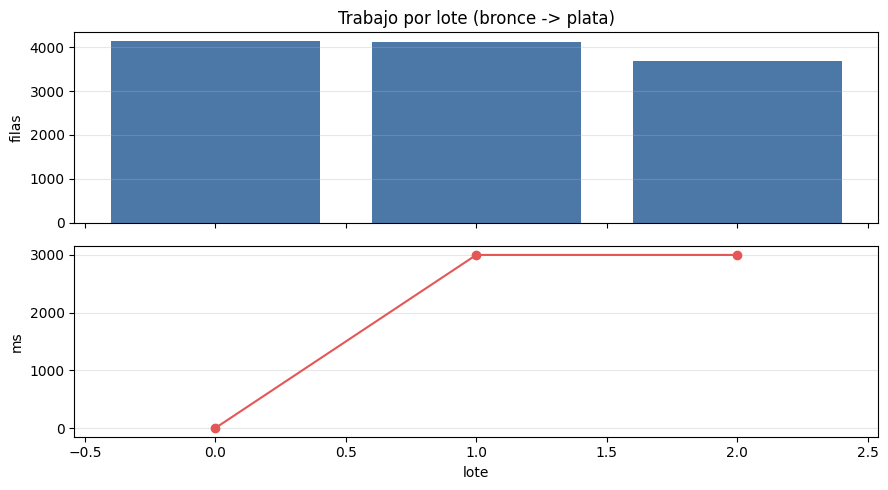

grafica guardada en /Volumes/workspace/default/telemetria/lake/rendimiento.png


In [0]:
import matplotlib.pyplot as plt

lotes  = progreso.get("bronce_a_plata", [])
ids    = [l["lote"] for l in lotes]
filas  = [l["filas"] for l in lotes]
tiempo = [l["ms"] for l in lotes]


# El primer lote incluye el arranque en frio y distorsiona la media, asi que se
# cuenta aparte. Por el camino del historial vale 0 y entonces no se menciona.
frio       = tiempo[0] if tiempo else 0
en_regimen = tiempo[1:] or tiempo

print(f"lotes procesados   {len(ids)}")
print(f"filas en total     {sum(filas):,}")
print(f"filas por lote     {sum(filas)/max(len(filas),1):.0f} de media, {max(filas, default=0)} maximo")
print(f"tiempo por lote    {sum(en_regimen)/max(len(en_regimen),1):.0f} ms de media")
if frio:
    print(f"arranque en frio   {frio} ms (primer lote, contado aparte)")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
a1.bar(ids, filas, color="#4c78a8")
a1.set_ylabel("filas"); a1.grid(axis="y", alpha=.3)
a1.set_title("Trabajo por lote (bronce -> plata)")
a2.plot(ids, tiempo, marker="o", color="#e45756")
a2.set_ylabel("ms"); a2.set_xlabel("lote"); a2.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(GRAFICA, dpi=120)
plt.show()
print("grafica guardada en", GRAFICA)

---
## 10. Registrar las tablas en el metastore

Hasta aquí las tablas son rutas, y se leen con ``delta.`ruta` ``. Registrarlas les da
nombre, las hace visibles en Catalog Explorer y permite consultarlas desde SQL sin
saber dónde están guardadas.

Unity Catalog no admite tablas externas cuya ubicación esté dentro de un Volume, así
que se crean gestionadas con `CREATE TABLE ... AS SELECT`. Son pocos datos y la copia
es inmediata.

In [0]:
tablas = {
    "iot_bronce":       BRONCE,
    "iot_plata":        PLATA,
    "iot_cuarentena":   CUARENTENA,
    "iot_oro_ciudades": ORO_CIUDAD,
    "iot_oro_calidad":  ORO_CALIDAD,
}

destino = f"{CATALOGO}.{ESQUEMA}" if ALMACEN == "volumes" else "default"

for nombre, camino in tablas.items():
    spark.sql(f"DROP TABLE IF EXISTS {destino}.{nombre}")
    spark.sql(f"CREATE TABLE {destino}.{nombre} AS SELECT * FROM delta.`{ruta(camino)}`")
    print("registrada:", f"{destino}.{nombre}")

display(spark.sql(f"SHOW TABLES IN {destino} LIKE 'iot_*'"))

registrada: workspace.default.iot_bronce
registrada: workspace.default.iot_plata
registrada: workspace.default.iot_cuarentena
registrada: workspace.default.iot_oro_ciudades
registrada: workspace.default.iot_oro_calidad


database,tableName,isTemporary
default,iot_bronce,false
default,iot_cuarentena,false
default,iot_oro_calidad,false
default,iot_oro_ciudades,false
default,iot_plata,false


In [0]:
%sql
-- Ya se puede consultar por nombre, sin saber donde estan los ficheros.
SELECT city,
       COUNT(*)                   AS eventos,
       ROUND(AVG(speed_kmh), 1)   AS velocidad_media,
       ROUND(AVG(battery_pct), 1) AS bateria_media
FROM   iot_plata
GROUP  BY city
ORDER  BY city

city,eventos,velocidad_media,bateria_media
Barcelona,2520,40.9,31.3
Bilbao,2319,38.6,30.7
Madrid,2411,38.9,32.5
Sevilla,2347,39.0,37.0
Valencia,2334,39.2,33.5


---
## 11. Conclusiones

Lo que se ha construido y dónde está cada cosa que pedía el enunciado:

| Lo que pedía el enunciado | Dónde está |
|---|---|
| Databricks Notebook | este fichero, ejecutado sobre un cluster de Databricks |
| Leer telemetría simulada en streaming | Sección 3, `readStream` sobre `landing/` |
| Desde almacenamiento cloud | Unity Catalog Volume (o DBFS), sección 1 |
| Parsear el JSON | Sección 3, esquema declarado a mano |
| Limpiar anomalías | Sección 4, seis reglas + tabla de cuarentena |
| Tabla Delta particionada por ciudad | Sección 4, `partitionBy("city")`; comprobado en 7.2 |

Limitaciones:

`foreachBatch` garantiza *al menos una vez*, no *exactamente una vez*. Si el proceso
se cayera después de escribir plata pero antes de confirmar el avance, ese lote se
reescribiría al reiniciar. Como cada evento tiene identificador único y los
duplicados se quitan antes, en la práctica no ocurre.

El watermark descarta eventos sin avisar. Es el precio de que la memoria de
duplicados no crezca sin límite, y por eso la comprobación 7.1 mide esa diferencia
en vez de dar la suma por buena.

Particionar por ciudad funciona porque son cinco valores. Por vehículo (1.590) o por
segundo darían miles de carpetas con un fichero minúsculo dentro.

### Qué cambia respecto a una ejecución local

| | Local (PySpark en el portátil) | Databricks |
|---|---|---|
| Sesión Spark | se crea a mano con `configure_spark_with_delta_pip` | ya viene dada en `spark` |
| Delta Lake | JAR descargado de Maven | integrado en el runtime |
| Almacenamiento | `file:///C:/...` | Volume de Unity Catalog o DBFS |
| Hadoop en Windows | `winutils.exe` + `hadoop.dll` a mano | no aplica |
| Generador | proceso aparte (`subprocess`) | hilo dentro del notebook |
| Trigger | `processingTime`, continuo | `availableNow`, serverless no admite continuo |
| Productor y consumidor | en paralelo | secuencial: genera, luego procesa |
| Lectura de landing | sin filtro | `pathGlobFilter` contra renombrados lentos |
| Compactación | solo `OPTIMIZE` manual | además `optimizeWrite`/`autoCompact`, apagados aquí a propósito |
| Catálogo | ninguno | Unity Catalog, sección 10 |
| Cierre | `spark.stop()` | **nunca**: mataría la sesión del cluster |

Las cifras concretas (filas procesadas, ficheros compactados, tiempos por lote)
dependen del cluster y no coincidirán con las de una ejecución local. El informe hay
que rellenarlo con los resultados de esta ejecución.

In [0]:
# Nada de spark.stop(): la sesion es del cluster.
print("Flujos parados:", not any(q.isActive for q in spark.streams.active))
print("Tablas escritas en:", ruta(LAGO))
for f in dbutils.fs.ls(ruta(LAGO)):
    print("  ", f.name)

Flujos parados: True
Tablas escritas en: /Volumes/workspace/default/telemetria/lake
   bronce/
   checkpoints/
   cuarentena/
   landing/
   oro_calidad/
   oro_ciudades/
   plata/
   rendimiento.png
